# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

### 0.0. Імпортуємо залежності

In [1]:
# Встановлюємо лише відсутні пакети. У Colab вони зазвичай уже є.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'torch>=2.2,<3', '--index-url',
                           'https://download.pytorch.org/whl/cpu'])
base_packages = {'numpy': 'numpy>=1.26,<3', 'pandas': 'pandas>=2.2,<4',
                 'matplotlib': 'matplotlib>=3.8,<4', 'IPython': 'ipython>=8'}
missing = [package for module, package in base_packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Основні залежності готові.')


Основні залежності готові.


In [2]:
import sys
import os
import random
import copy
import math
from pathlib import Path

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 110})
print(f'Python: {sys.version.split()[0]}')
print(f'NumPy: {np.__version__}; pandas: {pd.__version__}; PyTorch: {torch.__version__}')


Python: 3.13.18
NumPy: 2.1.3; pandas: 2.2.3; PyTorch: 2.11.0+cpu


### 0.1. Перевіряємо чи ми точно в Colab

In [3]:
IN_COLAB = 'google.colab' in sys.modules
print('Running in Colab:', IN_COLAB)
if not IN_COLAB:
    print('Локальний запуск: Google Drive буде замінено локальною папкою lab1.')
# Підтримуємо Run All поза Colab, як вимагають правила здачі наприкінці.


Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів)

In [4]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [5]:
def random_example():
    # Новий початковий список потрібен для коректного порівняння shuffle.
    numbers = list(range(10))
    number = random.randint(1, 100)
    random.shuffle(numbers)
    return number, numbers

print('1. Двічі ДО set_seed():')
for attempt in range(2):
    print(f'   Спроба {attempt + 1}:', random_example())

set_seed()
print('\nSeed зафіксовано:', SEED)
print('2. Двічі зі скиданням seed перед кожною генерацією:')
for attempt in range(2):
    set_seed()
    print(f'   Спроба {attempt + 1}:', random_example())

print('\n3. Двічі БЕЗ проміжного set_seed():')
set_seed()
for attempt in range(2):
    print(f'   Спроба {attempt + 1}:', random_example())

set_seed()  # Подальші вправи починаються з відтворюваного стану.


1. Двічі ДО set_seed():
   Спроба 1: (72, [0, 2, 5, 1, 7, 6, 4, 9, 8, 3])
   Спроба 2: (90, [6, 7, 4, 1, 8, 9, 0, 2, 5, 3])

Seed зафіксовано: 42
2. Двічі зі скиданням seed перед кожною генерацією:
   Спроба 1: (82, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])
   Спроба 2: (82, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])

3. Двічі БЕЗ проміжного set_seed():
   Спроба 1: (82, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])
   Спроба 2: (76, [4, 3, 2, 9, 5, 1, 7, 8, 0, 6])


**Пояснення до вправи 1.** `random` використовує псевдовипадковий генератор:
seed задає його початковий стан. До фіксації seed обидві пари результатів зазвичай
різні; окреме число `randint` може випадково повторитися. Якщо перед кожною
однаковою послідовністю операцій викликати `set_seed(42)`, повторюються і число,
і перестановка. Для `shuffle` кожного разу створюється однаковий вихідний список.
Без проміжного скидання генератор просувається далі, тому наступна пара інша.
Якщо перезапустити всю послідовність після `set_seed(42)`, вона відтвориться.
`set_seed()` також фіксує NumPy і PyTorch для наступних вправ.


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [6]:
device_available = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device = torch.device('cpu')

print('Доступний пристрій :', device_available)
print('Використовуємо     :', device)
if device_available.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

assert device.type == 'cpu', f'Навчання цієї лабораторної має бути на CPU: {device}'


Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [7]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ARTIFACT_DIR = Path('/content/drive/MyDrive/ai_systems/lab1')
else:
    current = Path.cwd()
    ARTIFACT_DIR = current if current.name == 'lab1' else current / 'lab1'

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR = ARTIFACT_DIR / 'runs'
RUNS_DIR.mkdir(exist_ok=True)
print('Артефакти зберігаються в:', ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [8]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)
for name, array in [('zeros_arr', zeros_arr), ('sevens_arr', sevens_arr)]:
    print(f'{name}:\n{array}\nshape={array.shape}, dtype={array.dtype}\n')


zeros_arr:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
shape=(3, 4), dtype=float64

sevens_arr:
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]]
shape=(3, 4), dtype=int64



**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [9]:
arange_arr = np.arange(0, 20, 2)  # Права межа 20 не включається (як у шаблоні).
linspace_arr = np.linspace(0, 1, 5)  # Обидві межі включаються.
print('arange:', arange_arr)
print('linspace:', linspace_arr)


arange: [ 0  2  4  6  8 10 12 14 16 18]
linspace: [0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [10]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))
print('Одинична матриця:\n', identity, '\nndim =', identity.ndim)
print('Випадкові цілі:\n', random_ints, '\nndim =', random_ints.ndim)


Одинична матриця:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] 
ndim = 2
Випадкові цілі:
 [[6 3 7]
 [4 6 9]
 [2 6 7]] 
ndim = 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [11]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])
mean = scores.mean()
std = scores.std(ddof=0)
z_scores = (scores - mean) / std
print('Середнє:', mean, ' Std:', std)
print('Z-scores:', np.round(z_scores, 4))
print(f'Після нормалізації: mean={z_scores.mean():.8f}, std={z_scores.std():.8f}')


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.288   0.3623  1.0125 -1.3098  0.8267 -0.6595  0.641   1.2912 -1.96
  0.0836]
Після нормалізації: mean=0.00000000, std=1.00000000


**Пояснення до вправи 6.** Використано стандартне відхилення всієї наданої
сукупності (`ddof=0`). Z-нормалізація виконується векторизовано:
`(scores - mean) / std`; її результат має середнє близько 0 і відхилення 1.


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [12]:
arr = np.arange(1, 13)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)
print(matrix)
print('Сума по рядках:  ', row_sums)
print('Сума по стовпцях:', col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [13]:
df = pd.DataFrame({
    'name': ['Олена', 'Андрій', 'Марія', 'Богдан', 'Софія', 'Данило'],
    'score': [95, 82, 74, 90, 67, 80],
})
top = df.loc[df['score'] > 80].sort_values('score', ascending=False)
print(top.to_string(index=False))


  name  score
 Олена     95
Богдан     90
Андрій     82


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [14]:
df['grade'] = np.select([df['score'] >= 90, df['score'] >= 75],
                        ['A', 'B'], default='C')
print(df.to_string(index=False))


  name  score grade
 Олена     95     A
Андрій     82     B
 Марія     74     C
Богдан     90     A
 Софія     67     C
Данило     80     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [15]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)
for name, tensor in [('zeros_t', zeros_t), ('sevens_t', sevens_t)]:
    print(f'{name}:\n{tensor}\nshape={tuple(tensor.shape)}, dtype={tensor.dtype}\n')


zeros_t:
tensor([[0., 0., 0.],
        [0., 0., 0.]])
shape=(2, 3), dtype=torch.float32

sevens_t:
tensor([[7, 7, 7],
        [7, 7, 7]])
shape=(2, 3), dtype=torch.int64



**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [16]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)
print('arange:', arange_t)
print('linspace:', linspace_t)


arange: tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
linspace: tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [17]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)
for name, tensor in [('from_list', from_list), ('random_t', random_t)]:
    print(f'{name}:\n{tensor}')
    print(f'shape={tuple(tensor.shape)}, dtype={tensor.dtype}, ndim={tensor.ndim}\n')


from_list:
tensor([[1, 2],
        [3, 4]])
shape=(2, 2), dtype=torch.int64, ndim=2

random_t:
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
shape=(3, 3), dtype=torch.float32, ndim=2



**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [18]:
n = 5.0
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()
print('Автоматичний градієнт:', x.grad.item())
print('Аналітичний градієнт:', 2 * n)
print('Збігаються:', math.isclose(x.grad.item(), 2 * n))


Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0
Збігаються: True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [19]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1
for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()
    if step in [0, 4, 9, 19]:
        print(f'Крок {step + 1:2d}: x={x.item():.6f}')
print(f'x = {x.item():.4f}  (мінімум у x=3)')
print(f'f(x) = {((x - 3) ** 2 + 5).item():.6f}  (мінімальне значення 5)')


Крок  1: x=0.600000
Крок  5: x=2.016960
Крок 10: x=2.677877
Крок 20: x=2.965412
x = 2.9654  (мінімум у x=3)
f(x) = 5.001196  (мінімальне значення 5)


**Пояснення до вправ 13–14.** Для `y=x²` autograd повертає `2x=10`.
У градієнтному спуску похідна дорівнює `2(x-3)`; крок з `lr=0.1` наближає
`x` до 3. За 20 кроків отримуємо приблизно `2.9654`, а не точний мінімум.
`torch.no_grad()` дозволяє оновити параметр, а `zero_()` прибирає попередній градієнт.


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

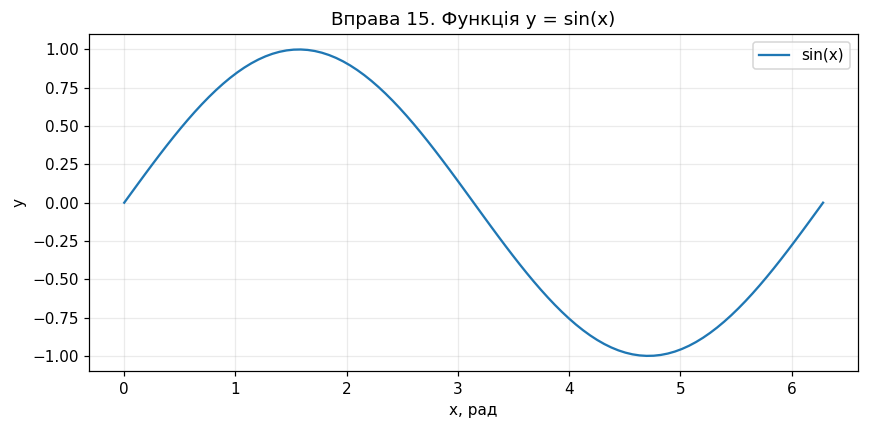

In [20]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.figure()
plt.plot(xs, np.sin(xs), color='C0', label='sin(x)')
plt.xlabel('x, рад')
plt.ylabel('y')
plt.title('Вправа 15. Функція y = sin(x)')
plt.legend()
plt.tight_layout()
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

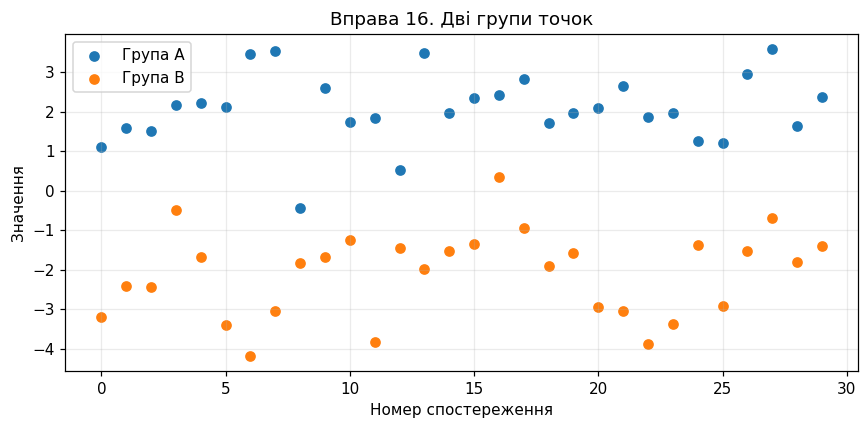

In [21]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2
plt.figure()
plt.scatter(np.arange(len(group_a)), group_a, color='C0', label='Група A')
plt.scatter(np.arange(len(group_b)), group_b, color='C1', label='Група B')
plt.xlabel('Номер спостереження')
plt.ylabel('Значення')
plt.title('Вправа 16. Дві групи точок')
plt.legend()
plt.tight_layout()
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [22]:
set_seed()
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300
x1 = torch.empty(TASK1_N, 1, device=device).uniform_(-5, 5)
noise = torch.randn(TASK1_N, 1, device=device)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise


**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

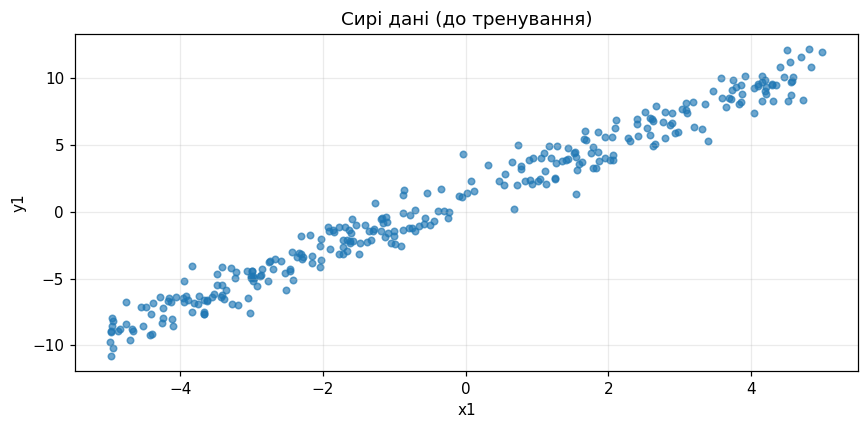

In [23]:
plt.figure()
plt.scatter(x1.numpy(), y1.numpy(), s=18, alpha=0.65)
plt.xlabel('x1')
plt.ylabel('y1')
plt.title('Сирі дані (до тренування)')
plt.tight_layout()
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [24]:
indices1 = torch.randperm(TASK1_N)
n_train1 = int(0.70 * TASK1_N)
n_val1 = int(0.15 * TASK1_N)
train_idx1 = indices1[:n_train1]
val_idx1 = indices1[n_train1:n_train1 + n_val1]
test_idx1 = indices1[n_train1 + n_val1:]
x_train1, y_train1 = x1[train_idx1], y1[train_idx1]
x_val1, y_val1 = x1[val_idx1], y1[val_idx1]
x_test1, y_test1 = x1[test_idx1], y1[test_idx1]
print(f'train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}')


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [25]:
task1_model = torch.nn.Linear(in_features=1, out_features=1).to(device)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()
x_line = torch.linspace(-5, 5, 100, device=device).unsqueeze(1)
snapshots = []

for epoch in range(100):
    task1_model.train()
    optimizer.zero_grad()
    y_pred = task1_model(x_train1)
    loss = loss_fn(y_pred, y_train1)
    loss.backward()
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        task1_model.eval()
        with torch.no_grad():
            y_line_pred = task1_model(x_line).clone()
            train_mse = loss_fn(task1_model(x_train1), y_train1).item()
            val_mse = loss_fn(task1_model(x_val1), y_val1).item()
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f'epoch {epoch:3d}  train MSE={train_mse:.4f}  val MSE={val_mse:.4f}  '
              f'w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  '
              f'b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})')

task1_model.eval()
with torch.no_grad():
    task1_test_mse = loss_fn(task1_model(x_test1), y_test1).item()
print(f'Підсумковий test MSE: {task1_test_mse:.4f}')


epoch   0  train MSE=2.9068  val MSE=3.1122  w=1.7073 (true 2.0)  b=-0.1046 (true 1.0)
epoch  30  train MSE=0.8733  val MSE=1.1209  w=2.0204 (true 2.0)  b=0.9961 (true 1.0)
epoch  60  train MSE=0.8708  val MSE=1.1108  w=2.0217 (true 2.0)  b=1.0441 (true 1.0)
epoch  90  train MSE=0.8708  val MSE=1.1105  w=2.0218 (true 2.0)  b=1.0462 (true 1.0)
epoch  99  train MSE=0.8708  val MSE=1.1105  w=2.0218 (true 2.0)  b=1.0462 (true 1.0)
Підсумковий test MSE: 1.1889


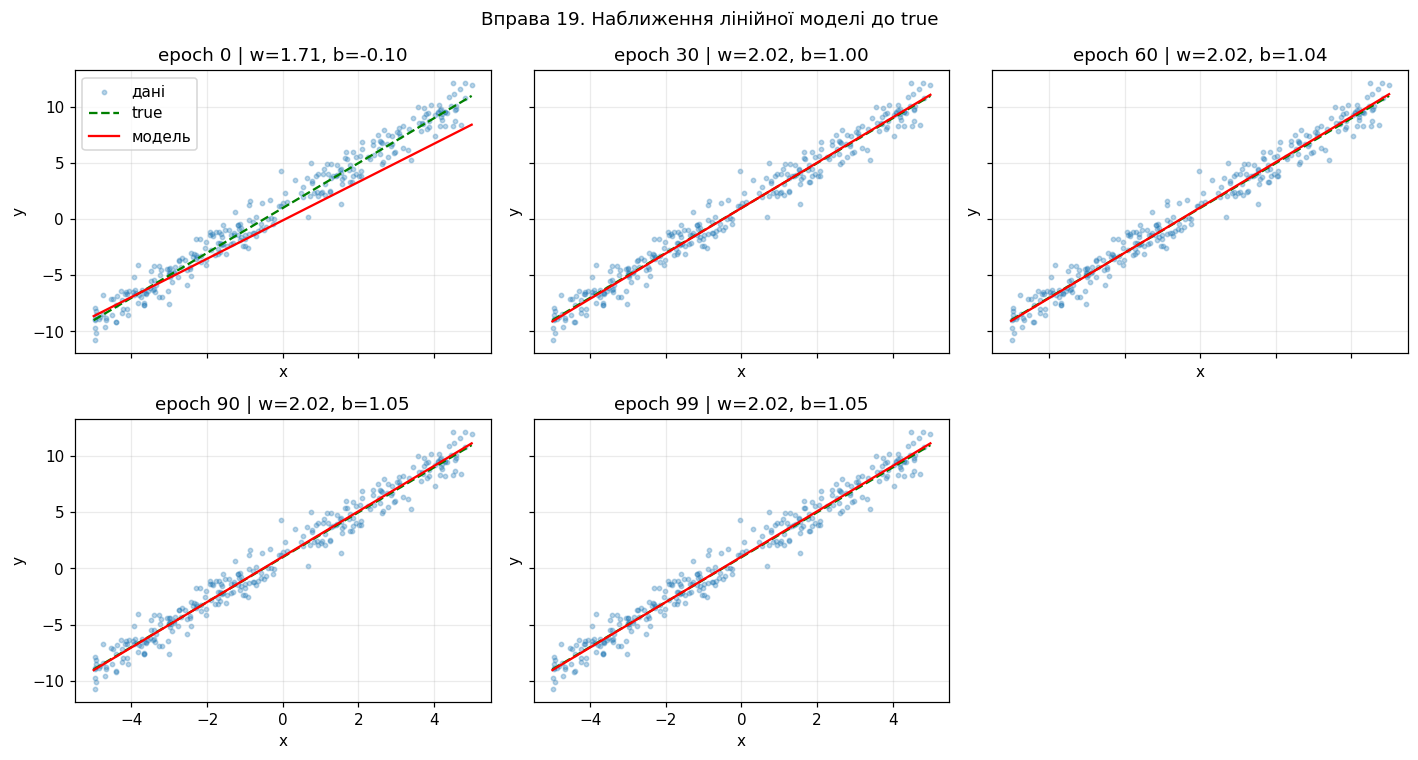

In [26]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes.flat, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label='дані')
    ax.plot(x_line.numpy(), y_line_true.numpy(), 'g--', label='true')
    ax.plot(x_line.numpy(), y_line_pred.numpy(), 'r-', label='модель')
    ax.set_title(f'epoch {epoch} | w={w:.2f}, b={b:.2f}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
axes.flat[-1].axis('off')
axes.flat[0].legend()
fig.suptitle('Вправа 19. Наближення лінійної моделі до true')
plt.tight_layout()
plt.show()


**Висновок до вправи 19.** Лінія моделі наближається до `y=2x+1`.
Через шум оцінені `w` і `b` не зобов'язані точно дорівнювати 2 і 1, а MSE
не має падати до нуля. Train використовується для градієнтів, validation —
для спостереження за якістю, test — для підсумкової оцінки.


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Власний сценарій: відстань поїздки → вартість таксі

Розглянемо умовний тариф у межах міста: **50 грн за подачу та 12 грн/км**.
Синтетична залежність: $y = 12x + 50 + \varepsilon$, де $x$ — відстань
від 0 до 30 км, $y$ — ціна в гривнях, $\varepsilon\sim\mathcal{N}(0,15^2)$.
Базова оплата покриває подачу, а кожен кілометр додає фіксовану суму;
шум умовно моделює очікування та невеликі відмінності маршруту.
Це навчальні припущення, а не реальні тарифи конкретного сервісу.

Створимо 400 спостережень, запишемо `dataset.csv` і прочитаємо його назад.
Поділ 70/15/15 дасть 280/60/60 спостережень. Для стабільного SGD
стандартизуємо **тільки x** за середнім і відхиленням **train**.
Обираємо найкращий стан моделі за validation MSE; test не бере участі
в навчанні чи виборі епохи. Логіку розділено на перевикористовувані функції.


In [27]:
def generate_dataset(n=400, seed=SEED):
    rng = np.random.default_rng(seed)
    distance = rng.uniform(0, 30, size=n)
    noise = rng.normal(0, 15, size=n)
    return pd.DataFrame({'distance_km': distance,
                         'price_uah': 12.0 * distance + 50.0 + noise})


def split_dataset(frame, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(frame), generator=generator)
    n_train = int(0.70 * len(frame))
    n_val = int(0.15 * len(frame))
    groups = [indices[:n_train], indices[n_train:n_train + n_val],
              indices[n_train + n_val:]]
    x = torch.tensor(frame[['distance_km']].to_numpy(), dtype=torch.float32, device=device)
    y = torch.tensor(frame[['price_uah']].to_numpy(), dtype=torch.float32, device=device)
    return {name: (x[idx], y[idx]) for name, idx in zip(['train', 'val', 'test'], groups)}


def fit_scaler(x_train):
    return {'mean': x_train.mean(dim=0, keepdim=True),
            'std': x_train.std(dim=0, unbiased=False, keepdim=True).clamp_min(1e-8)}


def transform_features(x, scaler):
    return (x - scaler['mean']) / scaler['std']


def train_regression(splits, epochs=300, lr=0.05, seed=SEED):
    set_seed(seed)
    model = torch.nn.Linear(1, 1).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    criterion = torch.nn.MSELoss()
    x_train, y_train = splits['train']
    x_val, y_val = splits['val']
    scaler = fit_scaler(x_train)
    x_train_scaled = transform_features(x_train, scaler)
    x_val_scaled = transform_features(x_val, scaler)
    history = []
    best_state, best_val, best_epoch = None, float('inf'), 0

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(x_train_scaled), y_train)
        loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            train_mse = criterion(model(x_train_scaled), y_train).item()
            val_mse = criterion(model(x_val_scaled), y_val).item()
        history.append({'epoch': epoch, 'train_mse': train_mse, 'val_mse': val_mse})
        if val_mse < best_val:
            best_val, best_epoch = val_mse, epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch in [1, 25, 50, 100, 200, epochs]:
            print(f'epoch {epoch:3d}: train MSE={train_mse:.3f}, val MSE={val_mse:.3f}')

    model.load_state_dict(best_state)
    model.eval()
    return model, scaler, pd.DataFrame(history), best_epoch


def evaluate_regression(model, x, y, scaler):
    model.eval()
    with torch.no_grad():
        prediction = model(transform_features(x, scaler))
        error = prediction - y
        mse = torch.mean(error ** 2).item()
        mae = torch.mean(torch.abs(error)).item()
        residual_ss = torch.sum(error ** 2).item()
        total_ss = torch.sum((y - y.mean()) ** 2).item()
    return {'MSE': mse, 'RMSE': math.sqrt(mse), 'MAE': mae,
            'R2': 1 - residual_ss / total_ss if total_ss > 0 else float('nan')}


dataset = generate_dataset()
DATASET_PATH = ARTIFACT_DIR / 'dataset.csv'
dataset.to_csv(DATASET_PATH, index=False, float_format='%.8f')
dataset = pd.read_csv(DATASET_PATH)
splits = split_dataset(dataset)
print('CSV збережено:', DATASET_PATH)
print('Рядків:', len(dataset), '| пропусків:', int(dataset.isna().sum().sum()))
print('train/val/test:', '/'.join(str(len(splits[key][0])) for key in ['train', 'val', 'test']))
display(dataset.head())


CSV збережено: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
Рядків: 400 | пропусків: 0
train/val/test: 280/60/60


,distance_km,price_uah
0,23.218681,335.218727
1,13.166353,215.859056
2,25.757938,363.239364
3,20.921041,279.861002
4,2.825320,49.252294


In [28]:
taxi_model, scaler, history, best_epoch = train_regression(splits)
validation_metrics = evaluate_regression(taxi_model, *splits['val'], scaler)
test_metrics = evaluate_regression(taxi_model, *splits['test'], scaler)

# Повертаємо коефіцієнти до одиниць початкового x (кілометри).
estimated_w = taxi_model.weight.item() / scaler['std'].item()
estimated_b = taxi_model.bias.item() - estimated_w * scaler['mean'].item()
print(f'\nНайкраща епоха за validation MSE: {best_epoch}')
print(f'Оцінена залежність: ціна = {estimated_w:.4f} * км + {estimated_b:.4f}')
print('Задано при генерації: ціна = 12.0 * км + 50.0')
display(pd.DataFrame([validation_metrics, test_metrics], index=['validation', 'test']).round(4))
history.to_csv(RUNS_DIR / 'training_history.csv', index=False)


epoch   1: train MSE=50003.090, val MSE=43557.145
epoch  25: train MSE=535.818, val MSE=501.945
epoch  50: train MSE=220.690, val MSE=216.995
epoch 100: train MSE=219.058, val MSE=214.687
epoch 200: train MSE=219.058, val MSE=214.683
epoch 300: train MSE=219.058, val MSE=214.683

Найкраща епоха за validation MSE: 139
Оцінена залежність: ціна = 12.1326 * км + 47.3016
Задано при генерації: ціна = 12.0 * км + 50.0


,MSE,RMSE,MAE,R2
validation,214.6826,14.6521,12.0219,0.9831
test,299.7331,17.3128,14.5622,0.9732


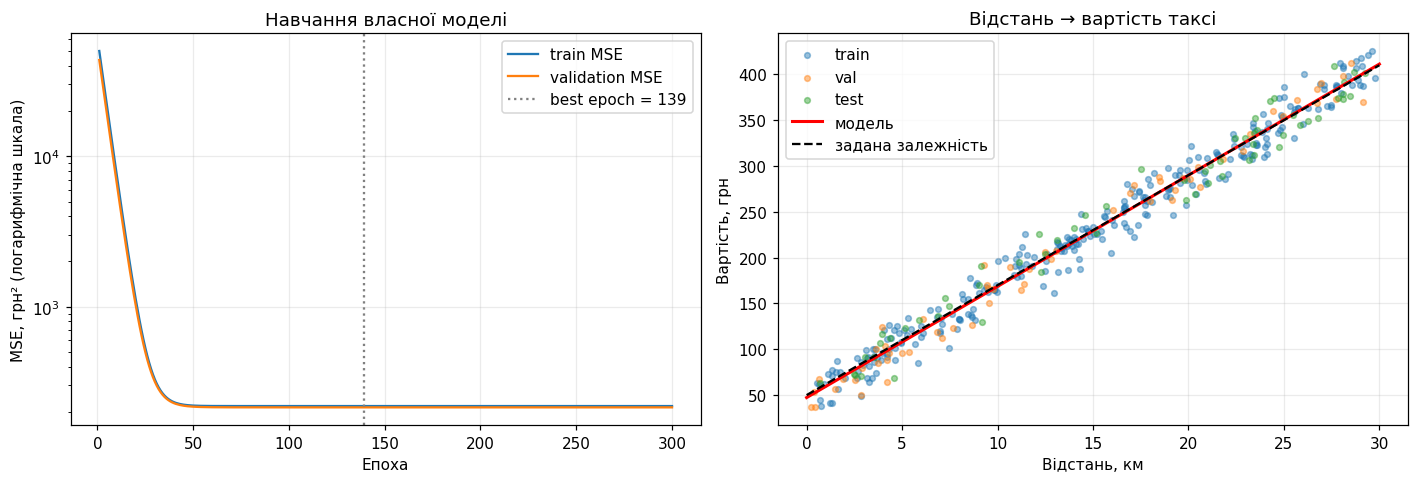

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history['epoch'], history['train_mse'], label='train MSE')
axes[0].plot(history['epoch'], history['val_mse'], label='validation MSE')
axes[0].axvline(best_epoch, color='gray', linestyle=':', label=f'best epoch = {best_epoch}')
axes[0].set_yscale('log')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('MSE, грн² (логарифмічна шкала)')
axes[0].set_title('Навчання власної моделі')
axes[0].legend()

colors = {'train': 'C0', 'val': 'C1', 'test': 'C2'}
for name, (x_part, y_part) in splits.items():
    axes[1].scatter(x_part.numpy().ravel(), y_part.numpy().ravel(),
                    s=14, alpha=0.45, color=colors[name], label=name)
distance_line = torch.linspace(0, 30, 150).unsqueeze(1)
with torch.no_grad():
    price_line = taxi_model(transform_features(distance_line, scaler))
axes[1].plot(distance_line.numpy(), price_line.numpy(), 'r-', linewidth=2, label='модель')
axes[1].plot(distance_line.numpy(), 12 * distance_line.numpy() + 50,
             'k--', linewidth=1.5, label='задана залежність')
axes[1].set_xlabel('Відстань, км')
axes[1].set_ylabel('Вартість, грн')
axes[1].set_title('Відстань → вартість таксі')
axes[1].legend()
plt.tight_layout()
plt.show()


**Висновок до вправи 20.** Коефіцієнт біля відстані показує доплату за 1 км,
а вільний член — базову оплату. Значення виведено в початкових одиницях,
попри стандартизацію входу. RMSE та MAE вимірюються в гривнях, MSE — у грн²;
R² оцінює пояснену варіацію. Шум обмежує можливу точність, тому оцінки
відрізняються від 12 і 50. Усі дані синтетичні.


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [30]:
MODEL_PATH = ARTIFACT_DIR / 'model.pt'
checkpoint = {
    'model_state_dict': taxi_model.state_dict(),
    'x_mean': scaler['mean'].cpu(),
    'x_std': scaler['std'].cpu(),
    'in_features': 1,
    'out_features': 1,
    'feature_name': 'distance_km',
    'target_name': 'price_uah',
    'seed': SEED,
    'best_epoch': best_epoch,
}
torch.save(checkpoint, MODEL_PATH)
print('Модель збережено:', MODEL_PATH)
print('Розмір файлу:', MODEL_PATH.stat().st_size, 'байт')
print('Збережено ваги, зміщення та параметри нормалізації train.')


Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt
Розмір файлу: 2569 байт
Збережено ваги, зміщення та параметри нормалізації train.


У `model.pt` записано словник із `state_dict` і параметрами масштабування.
Тому після завантаження моделі можна правильно обробити звичайну відстань у км.
У Colab цей файл створюється саме на Google Drive.


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [31]:
if importlib.util.find_spec('gradio') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gradio>=5,<7'])
import gradio as gr
print('Gradio:', gr.__version__)

loaded_checkpoint = torch.load(MODEL_PATH, map_location='cpu', weights_only=True)
loaded_model = torch.nn.Linear(loaded_checkpoint['in_features'],
                                loaded_checkpoint['out_features'])
loaded_model.load_state_dict(loaded_checkpoint['model_state_dict'])
loaded_model.eval()
loaded_scaler = {'mean': loaded_checkpoint['x_mean'], 'std': loaded_checkpoint['x_std']}

with torch.no_grad():
    restored_predictions = loaded_model(transform_features(splits['test'][0], loaded_scaler))
    original_predictions = taxi_model(transform_features(splits['test'][0], scaler))
max_difference = (restored_predictions - original_predictions).abs().max().item()
print(f'Максимальна різниця прогнозів після завантаження: {max_difference:.8f}')
assert torch.allclose(restored_predictions, original_predictions)


def predict_price(distance_km):
    value = float(distance_km)
    if not math.isfinite(value) or not 0 <= value <= 30:
        raise gr.Error('Вкажіть відстань від 0 до 30 км.')
    x_input = torch.tensor([[value]], dtype=torch.float32)
    with torch.no_grad():
        price = loaded_model(transform_features(x_input, loaded_scaler)).item()
    return round(price, 2)


demo = gr.Interface(
    fn=predict_price,
    inputs=gr.Slider(minimum=0, maximum=30, step=0.5, value=10, label='Відстань, км'),
    outputs=gr.Number(label='Прогноз вартості, грн'),
    title='Лабораторна 1 — прогноз вартості таксі',
    description='Введіть відстань поїздки від 0 до 30 км. Модель завантажено з model.pt. '
                'Приклад використовує синтетичні навчальні дані.',
    examples=[[0], [5], [10], [20], [30]],
    flagging_mode='never',
    analytics_enabled=False,
    api_name='predict',
)
print('Контрольний прогноз для 10 км:', predict_price(10), 'грн')


Gradio: 6.30.0
Максимальна різниця прогнозів після завантаження: 0.00000000
Контрольний прогноз для 10 км: 168.63 грн


In [32]:
RUN_GRADIO = os.environ.get('LAB1_RUN_GRADIO', '1') == '1'
if RUN_GRADIO:
    if 'launched_demo' in globals():
        launched_demo.close()
    demo.launch(share=IN_COLAB, inline=True, prevent_thread_lock=True,
                show_error=True)
    launched_demo = demo
else:
    print('Інтерфейс створено; сервер пропущено (LAB1_RUN_GRADIO=0).')


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://998f8343edd65d65cc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```

### Що підготувати перед здачею

1. Два обов'язкові скріншоти комірки **0.3**: CPU-сеанс та GPU-сеанс.
2. Додаткові скріншоти виконання: seed, таблиці, градієнти, графіки,
   тренування, метрики, збереження та Gradio. Точний перелік — у `README.md`.
3. Збережіть ноутбук **разом із результатами комірок** як `linear_models_lab.ipynb`.
4. Візьміть `dataset.csv` та `model.pt` з `MyDrive/ai_systems/lab1/`.
5. Викладіть файли у публічний GitHub-репозиторій за структурою з умови.
   Посилання на репозиторій подайте через форму викладача.

Скріншоти потрібно зробити під час власного запуску. Зображення графіків,
збережені всередині ноутбука, не заміняють два скріншоти CPU/GPU.
